In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
import spacy
import seaborn as sns

In [2]:
df = pd.read_csv('./data/emotions.txt', sep=';', header=None)

In [3]:
df = df.rename(columns={0: 'text', 1: 'emotion'})

In [4]:
df.head()

,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   text     16000 non-null  str  
 1   emotion  16000 non-null  str  
dtypes: str(2)
memory usage: 1.8 MB


In [6]:
nlp = spacy.load("en_core_web_sm") #prepared data 

text = "I am extremely happy about my new job."
doc = nlp(text)

for token in doc:
    print(token.text)

I
am
extremely
happy
about
my
new
job
.


In [7]:
# Apply spacy doc object to each row
df["doc"] = df["text"].apply(nlp)

In [8]:
# get individual words
df["tokens"] = df["doc"].apply(
    lambda doc: [token.text for token in doc]
)

In [9]:
# lemmatize words (get base words)
df["lemmas"] = df["doc"].apply(
    lambda doc: [token.lemma_ for token in doc]
)

In [10]:
df["clean_tokens"] = df["doc"].apply(
    lambda doc: [
        token.lemma_.lower()
        for token in doc
        if not token.is_punct and token.lemma_.lower() not in nlp.Defaults.stop_words
    ]
)

In [11]:
# extract adjectives
df["adjectives"] = df["doc"].apply(
    lambda doc: [
        token.text
        for token in doc
        if token.pos_ == "ADJ"
    ]
)

In [12]:
# create column of negated words. If "not" appears before a word, it will be come "not_word"

negations = {"not", "no", "never", "n't"}

def process_doc(doc):
    tokens = []
    
    for i, token in enumerate(doc):
        if token.is_punct:
            continue
            
        word = token.lemma_.lower()

        if word in negations and i + 1 < len(doc):
            next_word = doc[i + 1].lemma_.lower()
            tokens.append(f"not_{next_word}")
        elif i > 0 and doc[i - 1].lemma_.lower() in negations:
            continue
        elif not token.is_stop:
            tokens.append(word)
            
    return tokens

df["clean_tokens_neg"] = df["doc"].apply(process_doc)

# count words in each cleaned sentence
# using the same spaCy document logic as the other text columns
# this is saved out with the cleaned dataset
df["word_count"] = df["doc"].apply(
    lambda doc: len([token for token in doc if not token.is_punct and not token.is_space])
)

In [13]:
df.head()

,text,emotion,doc,tokens,lemmas,clean_tokens,adjectives,clean_tokens_neg,word_count
0,i didnt feel humiliated,sadness,"(i, did, nt, feel, humiliated)","[i, did, nt, feel, humiliated]","[I, do, not, feel, humiliated]","[feel, humiliated]",[humiliated],"[not_feel, humiliated]",5
1,i can go from feeling so hopeless to so damned...,sadness,"(i, can, go, from, feeling, so, hopeless, to, ...","[i, can, go, from, feeling, so, hopeless, to, ...","[I, can, go, from, feel, so, hopeless, to, so,...","[feel, hopeless, damned, hopeful, care, awake]","[hopeless, hopeful, awake]","[feel, hopeless, damned, hopeful, care, awake]",21
2,im grabbing a minute to post i feel greedy wrong,anger,"(i, m, grabbing, a, minute, to, post, i, feel,...","[i, m, grabbing, a, minute, to, post, i, feel,...","[I, m, grab, a, minute, to, post, I, feel, gre...","[m, grab, minute, post, feel, greedy, wrong]","[greedy, wrong]","[m, grab, minute, post, feel, greedy, wrong]",11
3,i am ever feeling nostalgic about the fireplac...,love,"(i, am, ever, feeling, nostalgic, about, the, ...","[i, am, ever, feeling, nostalgic, about, the, ...","[I, be, ever, feel, nostalgic, about, the, fir...","[feel, nostalgic, fireplace, know, property]",[nostalgic],"[feel, nostalgic, fireplace, know, property]",18
4,i am feeling grouchy,anger,"(i, am, feeling, grouchy)","[i, am, feeling, grouchy]","[I, be, feel, grouchy]","[feel, grouchy]",[grouchy],"[feel, grouchy]",4


In [14]:
# group adjectives by emotion in that row
df.groupby("emotion")["adjectives"].apply(list)

emotion
anger       [[greedy, wrong], [grouchy], [easiest, dissati...
fear        [[confused, old], [compromised, skeptical], [o...
joy         [[huge], [divine, spiritual], [immense, genera...
love        [[nostalgic], [romantic], [sad, first], [gentl...
sadness     [[humiliated], [hopeless, hopeful, awake], [li...
surprise    [[asleep, funny], [past, impressed, more, few]...
Name: adjectives, dtype: object

In [15]:
# count sentences in words
df["word_count"] = df["doc"].apply(
    lambda doc: len([token for token in doc if not token.is_punct])
)

In [16]:
df.head()

,text,emotion,doc,tokens,lemmas,clean_tokens,adjectives,clean_tokens_neg,word_count
0,i didnt feel humiliated,sadness,"(i, did, nt, feel, humiliated)","[i, did, nt, feel, humiliated]","[I, do, not, feel, humiliated]","[feel, humiliated]",[humiliated],"[not_feel, humiliated]",5
1,i can go from feeling so hopeless to so damned...,sadness,"(i, can, go, from, feeling, so, hopeless, to, ...","[i, can, go, from, feeling, so, hopeless, to, ...","[I, can, go, from, feel, so, hopeless, to, so,...","[feel, hopeless, damned, hopeful, care, awake]","[hopeless, hopeful, awake]","[feel, hopeless, damned, hopeful, care, awake]",21
2,im grabbing a minute to post i feel greedy wrong,anger,"(i, m, grabbing, a, minute, to, post, i, feel,...","[i, m, grabbing, a, minute, to, post, i, feel,...","[I, m, grab, a, minute, to, post, I, feel, gre...","[m, grab, minute, post, feel, greedy, wrong]","[greedy, wrong]","[m, grab, minute, post, feel, greedy, wrong]",11
3,i am ever feeling nostalgic about the fireplac...,love,"(i, am, ever, feeling, nostalgic, about, the, ...","[i, am, ever, feeling, nostalgic, about, the, ...","[I, be, ever, feel, nostalgic, about, the, fir...","[feel, nostalgic, fireplace, know, property]",[nostalgic],"[feel, nostalgic, fireplace, know, property]",18
4,i am feeling grouchy,anger,"(i, am, feeling, grouchy)","[i, am, feeling, grouchy]","[I, be, feel, grouchy]","[feel, grouchy]",[grouchy],"[feel, grouchy]",4


/tmp/ipykernel_432944/2027361697.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_20_words.values, y=top_20_words.index, palette='viridis')


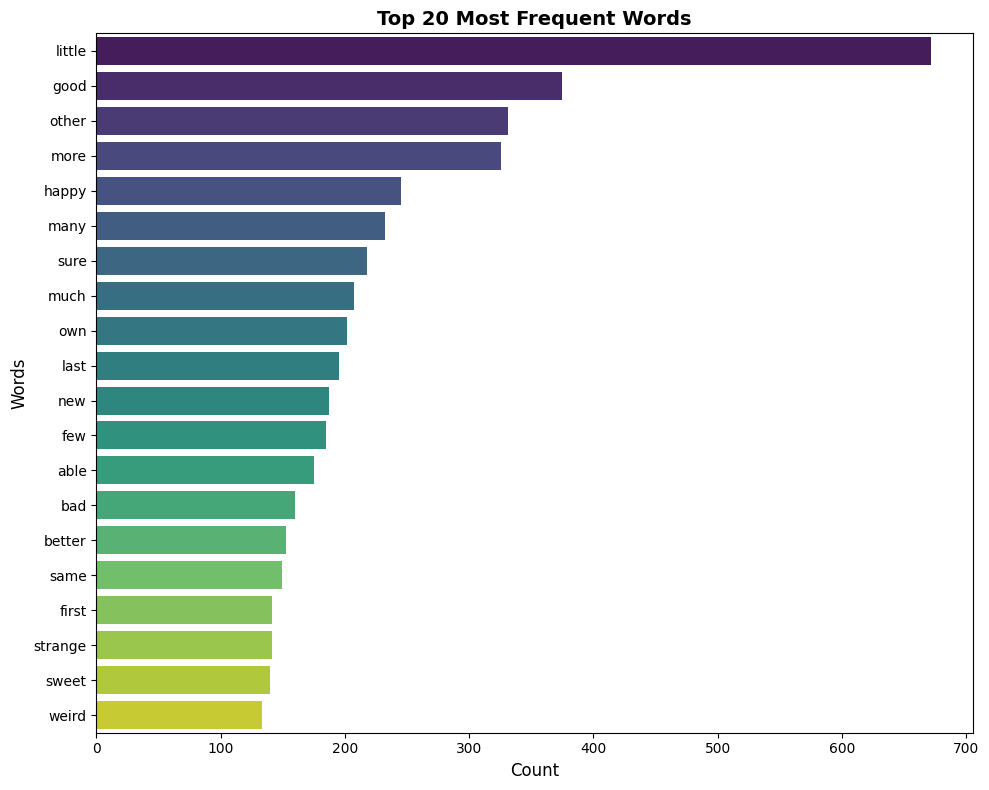

In [17]:
top_20_words = df['adjectives'].explode().value_counts().head(20)

# 2. Plot the top 20 data
plt.figure(figsize=(10, 8))  # Slightly taller to fit 20 labels comfortably
sns.barplot(x=top_20_words.values, y=top_20_words.index, palette='viridis')

# 3. Customize the chart
plt.title('Top 20 Most Frequent Words', fontsize=14, fontweight='bold')
plt.xlabel('Count', fontsize=12)
plt.ylabel('Words', fontsize=12)

plt.tight_layout()  # Ensures long word labels don't get cut off
plt.show()

In [18]:
df.head()

,text,emotion,doc,tokens,lemmas,clean_tokens,adjectives,clean_tokens_neg,word_count
0,i didnt feel humiliated,sadness,"(i, did, nt, feel, humiliated)","[i, did, nt, feel, humiliated]","[I, do, not, feel, humiliated]","[feel, humiliated]",[humiliated],"[not_feel, humiliated]",5
1,i can go from feeling so hopeless to so damned...,sadness,"(i, can, go, from, feeling, so, hopeless, to, ...","[i, can, go, from, feeling, so, hopeless, to, ...","[I, can, go, from, feel, so, hopeless, to, so,...","[feel, hopeless, damned, hopeful, care, awake]","[hopeless, hopeful, awake]","[feel, hopeless, damned, hopeful, care, awake]",21
2,im grabbing a minute to post i feel greedy wrong,anger,"(i, m, grabbing, a, minute, to, post, i, feel,...","[i, m, grabbing, a, minute, to, post, i, feel,...","[I, m, grab, a, minute, to, post, I, feel, gre...","[m, grab, minute, post, feel, greedy, wrong]","[greedy, wrong]","[m, grab, minute, post, feel, greedy, wrong]",11
3,i am ever feeling nostalgic about the fireplac...,love,"(i, am, ever, feeling, nostalgic, about, the, ...","[i, am, ever, feeling, nostalgic, about, the, ...","[I, be, ever, feel, nostalgic, about, the, fir...","[feel, nostalgic, fireplace, know, property]",[nostalgic],"[feel, nostalgic, fireplace, know, property]",18
4,i am feeling grouchy,anger,"(i, am, feeling, grouchy)","[i, am, feeling, grouchy]","[I, be, feel, grouchy]","[feel, grouchy]",[grouchy],"[feel, grouchy]",4


In [19]:
# Option 1: Load via a specific model
nlp = spacy.load("en_core_web_sm")
print(nlp.Defaults.stop_words)

# Option 2: Import directly without loading a full model pipeline
from spacy.lang.en.stop_words import STOP_WORDS
print(STOP_WORDS)

{'can', 'though', 'whenever', 'former', 'further', 'hundred', 'whatever', 'why', 'every', 'whoever', 'say', '‘d', '‘ve', 'them', 'give', 'himself', '’m', 'due', 'various', 'thereby', 'few', 'not', 'side', 'nowhere', 'anywhere', 'above', 'a', 'in', 'made', 'at', 'whereupon', 'seemed', 'thereafter', 'show', 'noone', 'please', 'quite', 'was', 'she', 'still', 'almost', 'really', 'towards', 'nevertheless', 'our', 'to', 'someone', 'your', 'will', 'thence', 'very', 'between', 'become', 'while', 'any', 'see', 'so', 'therefore', 'how', 'over', 'each', 'did', 'yours', 'serious', 'we', 'all', 'these', 'this', 'are', 'ever', 'n‘t', 'yet', 'ca', 'both', 'rather', 'none', 'thru', 'fifty', 'regarding', 'moreover', 'latterly', 'below', 'indeed', 'less', "'re", 'hereafter', 'elsewhere', 'meanwhile', 'seem', 'upon', '’ve', 'full', 'across', 'without', 'from', 'herein', 'using', 'more', 'seems', 'may', 'nor', 'much', 'do', 'others', "'ve", 'four', 'ourselves', 'formerly', 'whom', 'hereupon', '’d', 'aroun

In [20]:
# Words you want to test
test_words = ['not', 'never', 'no']

for word in test_words:
    # Always normalize to lowercase for accurate lookup
    is_stop = word.lower() in STOP_WORDS
    print(f"'{word}': {is_stop}")

'not': True
'never': True
'no': True


In [21]:
print(nlp("not")[0].is_stop)

True


/tmp/ipykernel_432944/3939699781.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=avg_word_count.index, y=avg_word_count.values, palette='Set2')


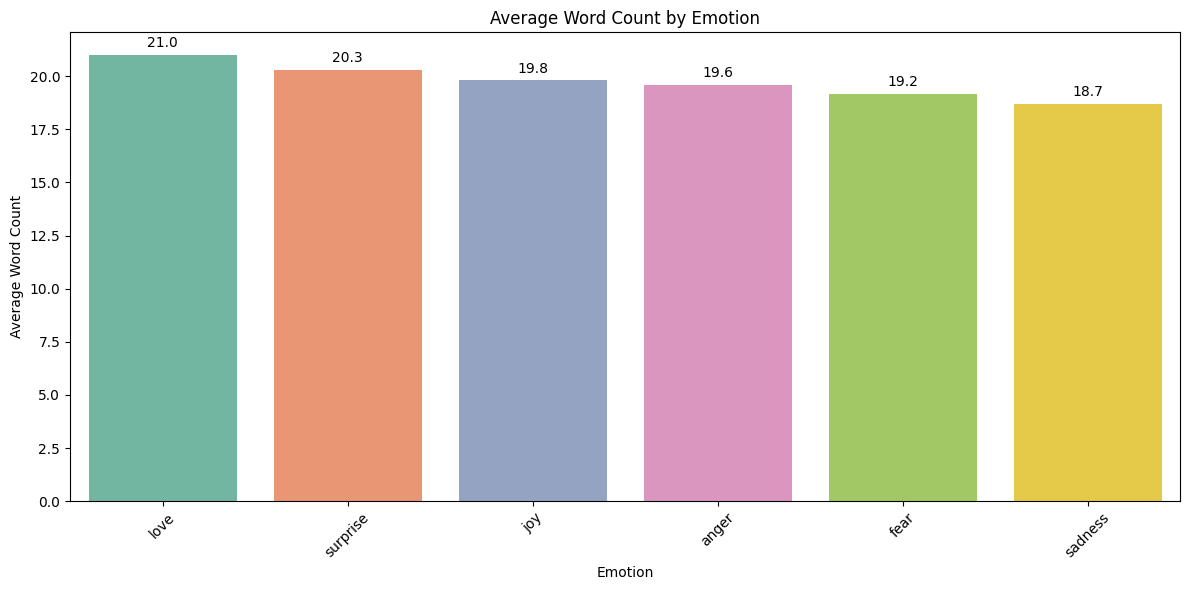

In [24]:
# Plot average word count by emotion
avg_word_count = df.groupby('emotion')['word_count'].mean().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
ax = sns.barplot(x=avg_word_count.index, y=avg_word_count.values, palette='Set2')

plt.title('Average Word Count by Emotion')
plt.xlabel('Emotion')
plt.ylabel('Average Word Count')
plt.xticks(rotation=45)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f', padding=3)
plt.tight_layout()
plt.show()

/tmp/ipykernel_432944/2182915066.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=emotion_counts.index, y=emotion_counts.values, palette='viridis')


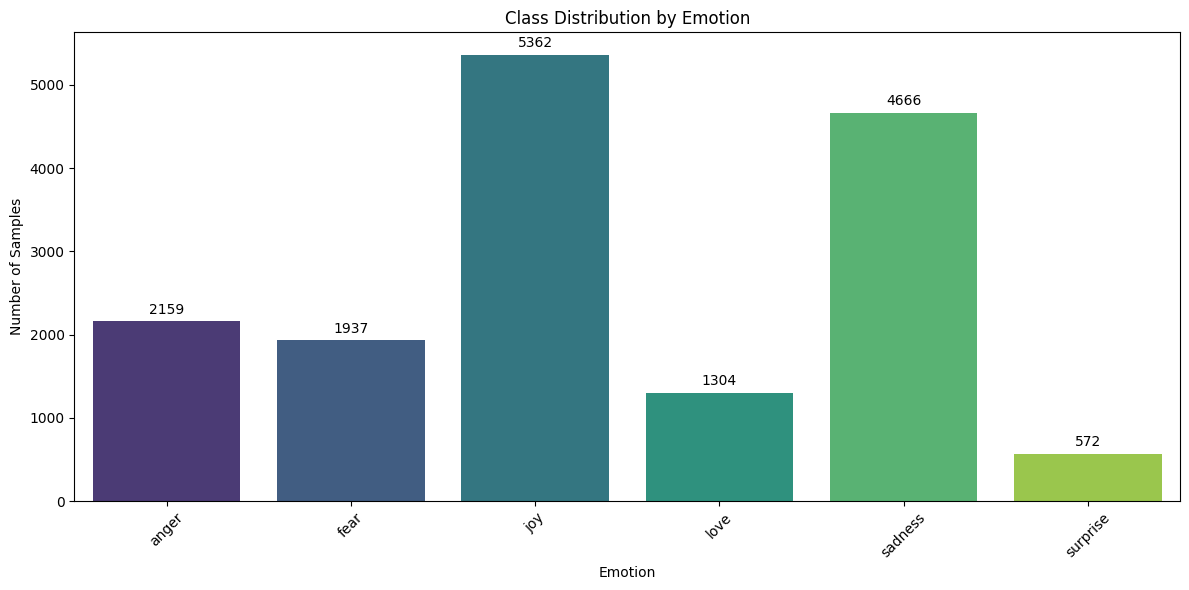

In [25]:
# Plot class imbalance by emotion
emotion_counts = df['emotion'].value_counts().sort_index()

plt.figure(figsize=(12, 6))
ax = sns.barplot(x=emotion_counts.index, y=emotion_counts.values, palette='viridis')

plt.title('Class Distribution by Emotion')
plt.xlabel('Emotion')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45)
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)
plt.tight_layout()
plt.show()

In [22]:
df.to_csv('./data/emotions_clean.csv')